In [1]:
import sys
sys.path.append("..")
from pathlib import Path
import duckdb, mlflow, shap
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.features import ORDERING_FEATURES, STATIC, VITAL_FEATS, LAB_FEATS

ROOT = Path("..").resolve()
mlflow.set_tracking_uri(f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}")

# Most recent finished run named "lgbm"
runs = mlflow.search_runs(
    experiment_names=["sepsis-early-warning"],
    filter_string="tags.`mlflow.runName` = 'lgbm' and attributes.status = 'FINISHED'",
    order_by=["attributes.start_time DESC"],
)
run_id = runs.iloc[0]["run_id"]
model = mlflow.lightgbm.load_model(f"runs:/{run_id}/model")
feats = mlflow.artifacts.load_text(f"runs:/{run_id}/features.txt").split("\n")

con = duckdb.connect(str(ROOT / "data" / "sepsis.duckdb"), read_only=True)
val = con.execute(
    f"SELECT patient_id, ICULOS, SepsisLabel, {', '.join(feats)} FROM features WHERE split = 'val'"
).df()
cohort = con.execute(
    "SELECT patient_id, septic, onset_iculos FROM cohort WHERE split = 'val'"
).df()
preds = pd.read_parquet(ROOT / "data" / "predictions" / "lgbm_val.parquet")

X = val[feats].astype("float32")
print("Run:", run_id, "| features:", len(feats), "| validation rows:", len(X))

Run: 8eb22f64550f4aaa813a9a521a0fc3f9 | features: 148 | validation rows: 119450


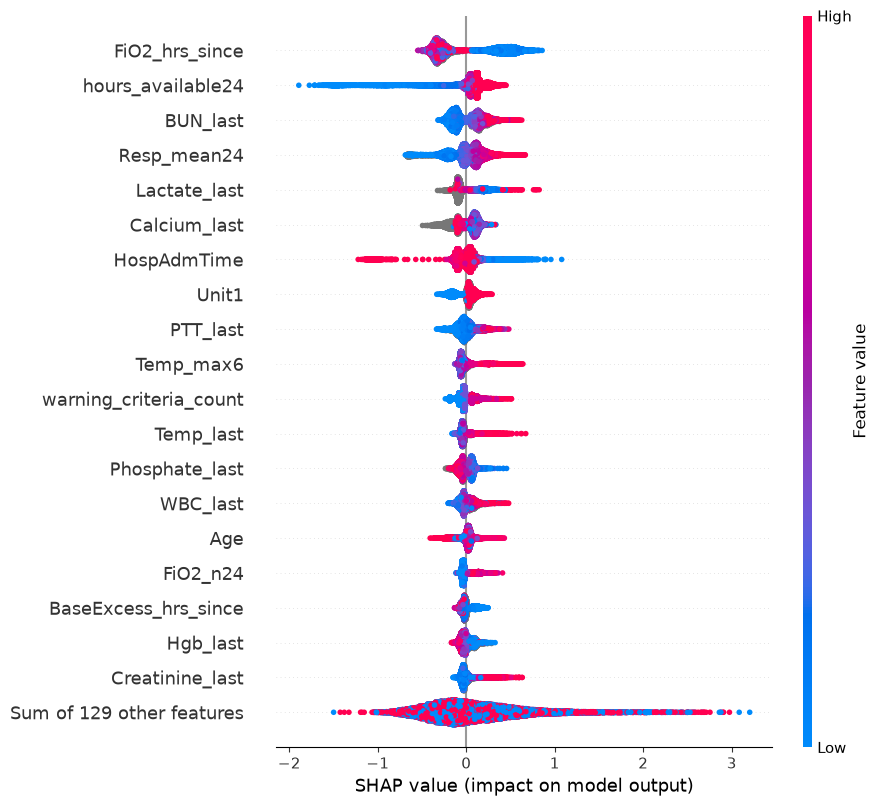

In [2]:
sample = X.sample(20000, random_state=0)      # SHAP on all 120k rows is slow; 20k is plenty
explainer = shap.TreeExplainer(model)
sv = explainer(sample)

shap.plots.beeswarm(sv, max_display=20)

In [3]:
imp = pd.Series(np.abs(sv.values).mean(axis=0), index=feats).sort_values(ascending=False)

def group(f):
    if f in ORDERING_FEATURES:
        return "ordering (labs)"
    if f.endswith("_delta6_24") or f.endswith("_change24"):
        return "change"
    if f in STATIC:
        return "static"
    prefix = f.split("_")[0]
    if prefix in VITAL_FEATS:
        return "vital levels"
    if prefix in LAB_FEATS:
        return "lab values"
    return "clinical / context"

print(imp.groupby(imp.index.map(group)).sum().sort_values(ascending=False).round(3))
print("\nTop 15 features:\n", imp.head(15).round(4))

lab values            1.022
vital levels          0.895
ordering (labs)       0.754
clinical / context    0.329
static                0.324
change                0.320
dtype: float64

Top 15 features:
 FiO2_hrs_since            0.3593
hours_available24         0.1872
BUN_last                  0.1463
Resp_mean24               0.1436
Lactate_last              0.1256
Calcium_last              0.1099
HospAdmTime               0.1005
Unit1                     0.0813
PTT_last                  0.0768
Temp_max6                 0.0719
warning_criteria_count    0.0690
Temp_last                 0.0650
Phosphate_last            0.0618
WBC_last                  0.0600
Age                       0.0579
dtype: float64


         count   mean    std    min    25%    50%    75%    max
septic                                                         
0       2782.0  0.030  0.045  0.001  0.007  0.014  0.034  0.552
1        238.0  0.119  0.133  0.002  0.030  0.069  0.164  0.787


,septic,max_risk,hours
patient_id,,,
p013365,1,0.002307,12
p017354,1,0.003830,13
p020593,1,0.004545,11
p017806,1,0.005123,7
p013013,1,0.005215,14


,septic,max_risk,hours
patient_id,,,
p019137,0,0.551516,45
p002239,0,0.476579,54
p008132,0,0.440495,336
p019442,0,0.438756,39
p006037,0,0.421983,39


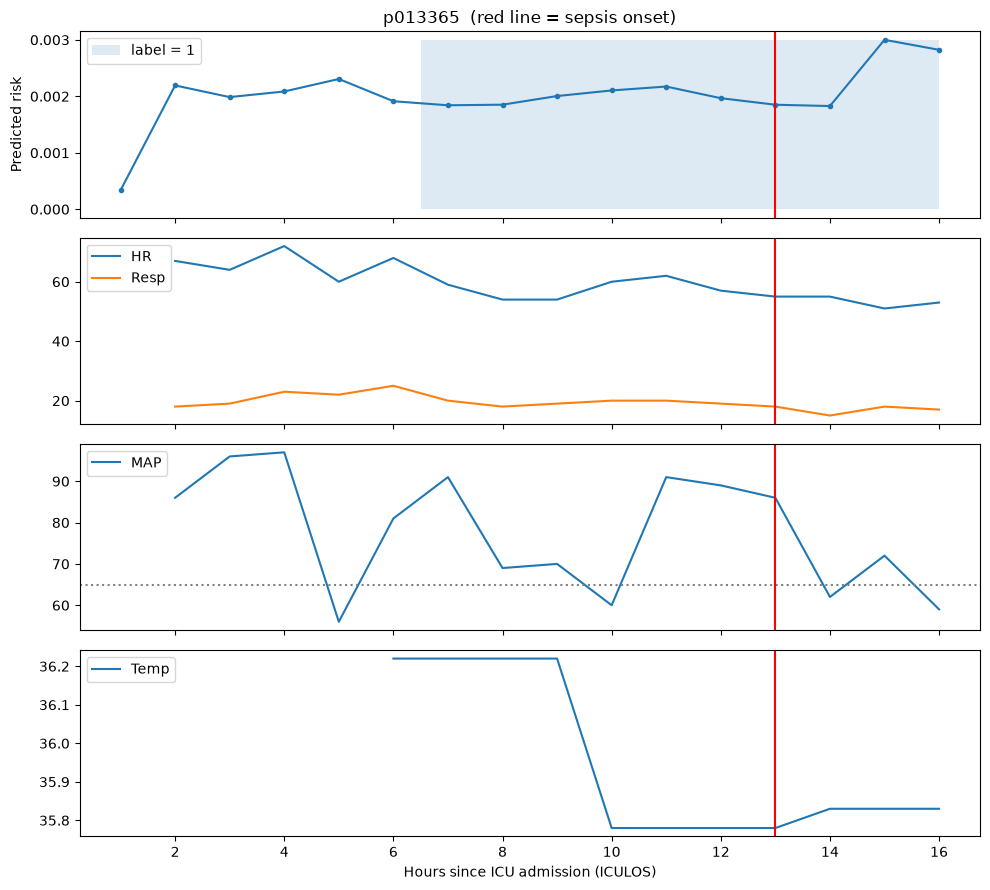

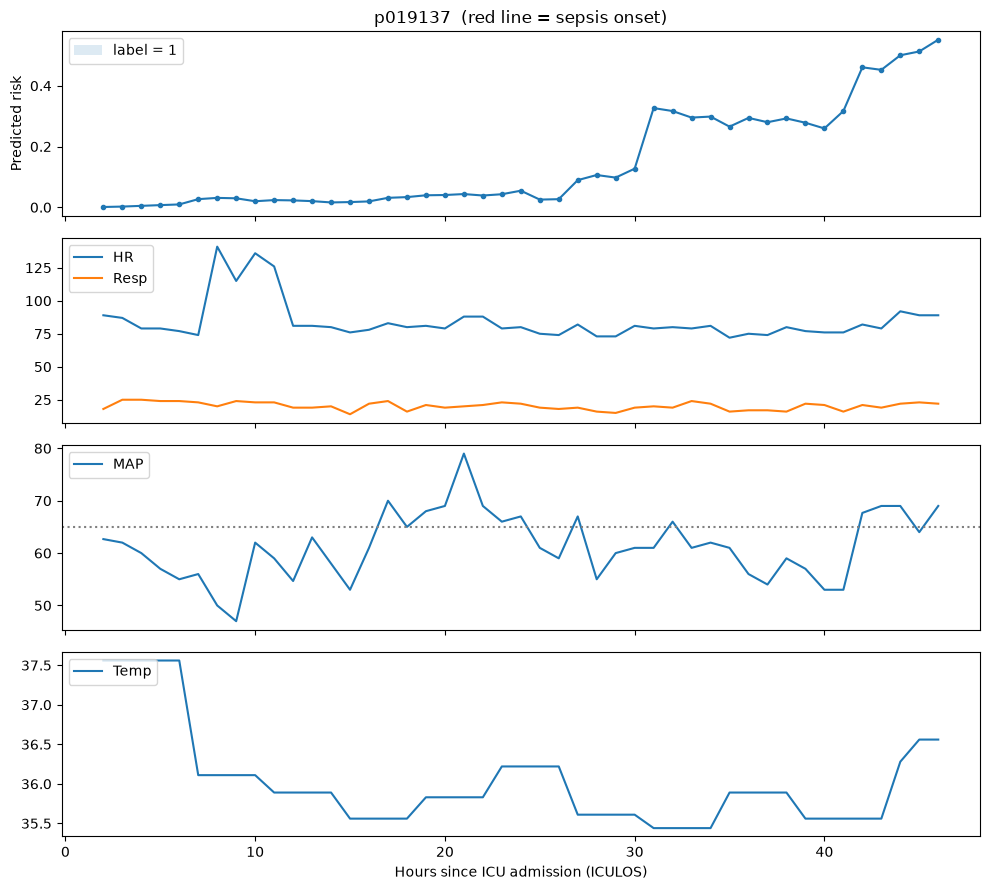

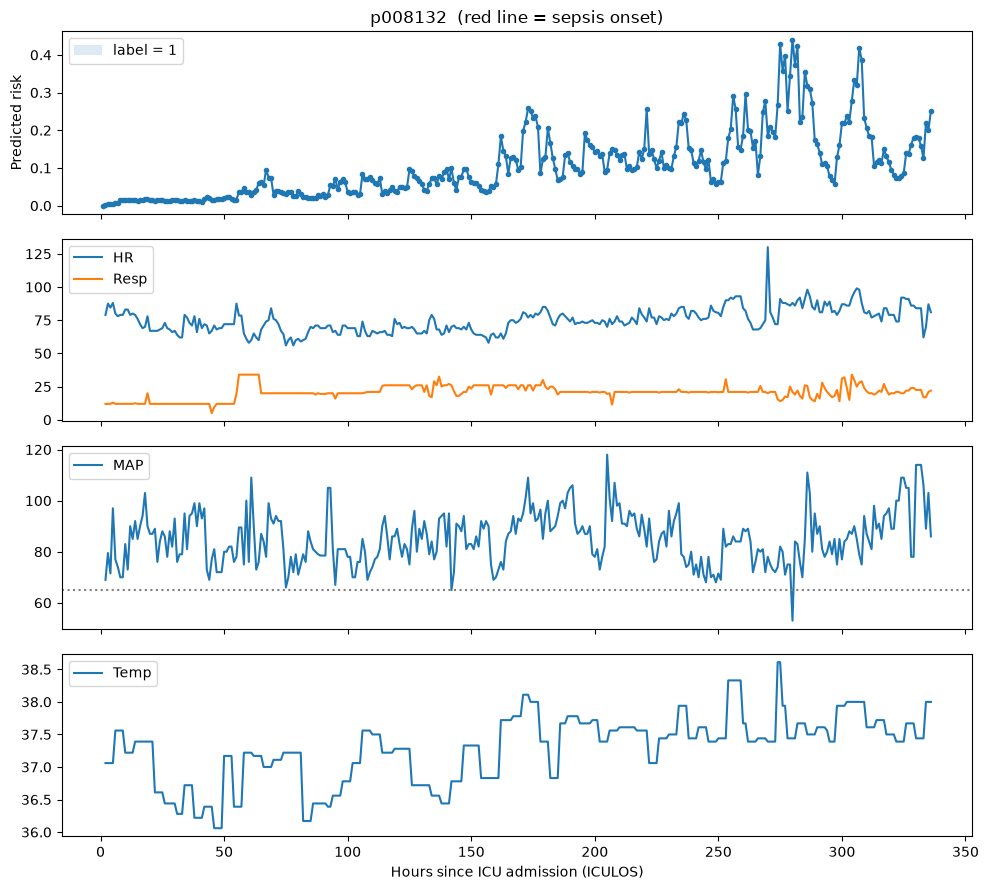

In [4]:
# --- Patient-level error analysis ---
df = preds.merge(cohort, on="patient_id")
# Only hours before onset count as "early warning"; for non-septic patients, every hour counts
df["pre_onset"] = (df["septic"] == 0) | (df["ICULOS"] < df["onset_iculos"])

pt = (df[df["pre_onset"]]
      .groupby("patient_id")
      .agg(septic=("septic", "first"), max_risk=("p", "max"), hours=("p", "size")))

print(pt.groupby("septic")["max_risk"].describe().round(3))

missed = pt[pt["septic"] == 1].nsmallest(5, "max_risk")       # septic, but risk stayed low
false_alarms = pt[pt["septic"] == 0].nlargest(5, "max_risk")  # not septic, but high risk
display(missed, false_alarms)

# --- Plot and save individual patients ---
FIG_DIR = Path("../reports/figures/after_fix")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def plot_patient(pid):
    d = df[df["patient_id"] == pid].sort_values("ICULOS")
    f = val[val["patient_id"] == pid].sort_values("ICULOS")
    onset = d["onset_iculos"].iloc[0]

    fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
    axes[0].plot(d["ICULOS"], d["p"], marker=".")
    axes[0].set_ylabel("Predicted risk")
    axes[0].fill_between(d["ICULOS"], 0, d["y"] * d["p"].max(), step="mid", alpha=0.15, label="label = 1")
    axes[0].legend(loc="upper left")
    axes[1].plot(f["ICULOS"], f["HR_last"], label="HR")
    axes[1].plot(f["ICULOS"], f["Resp_last"], label="Resp")
    axes[1].legend(loc="upper left")
    axes[2].plot(f["ICULOS"], f["MAP_last"], label="MAP")
    axes[2].axhline(65, linestyle=":", color="gray")
    axes[2].legend(loc="upper left")
    axes[3].plot(f["ICULOS"], f["Temp_last"], label="Temp")
    axes[3].legend(loc="upper left")
    for ax in axes:
        if pd.notna(onset):
            ax.axvline(onset, color="red")
    axes[0].set_title(f"{pid}  (red line = sepsis onset)")
    axes[-1].set_xlabel("Hours since ICU admission (ICULOS)")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"risk_{pid}.png", dpi=150, bbox_inches="tight")
    plt.show()

plot_patient(missed.index[0])         # a missed septic patient
plot_patient(false_alarms.index[0])   # the top false alarm
plot_patient("p008132")               # the long-stay false alarm from before the fix

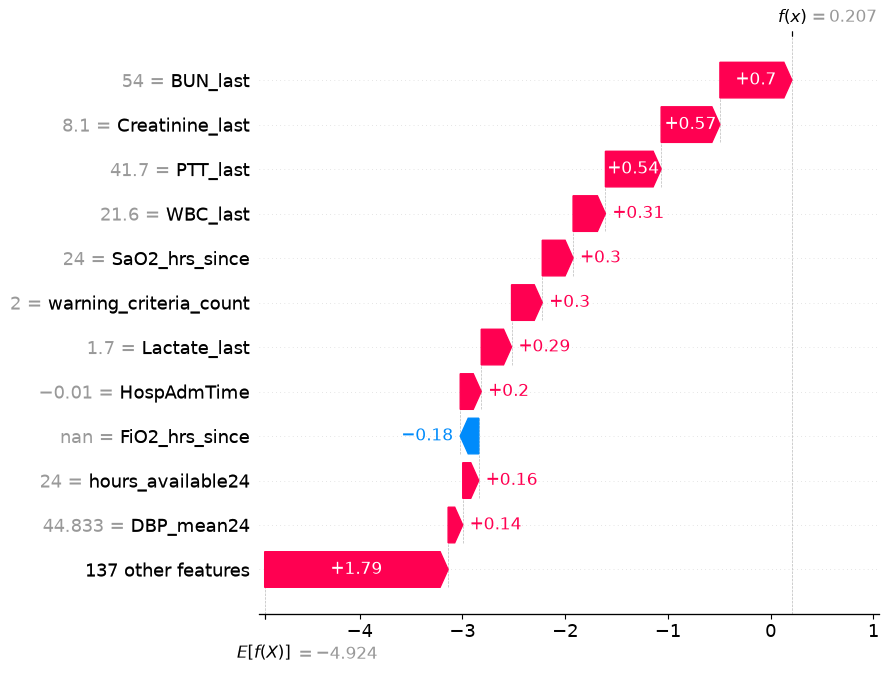

In [5]:
pid = false_alarms.index[0]
rows = df[(df["patient_id"] == pid)]
peak_idx = rows["p"].idxmax()                       # the hour with the highest risk
x_row = X.loc[[peak_idx]]
shap.plots.waterfall(explainer(x_row)[0], max_display=12)

## Findings (after capping hours-since features at 24 h)
- Clock removed: Lactate_hrs_since left the top 20; remaining hours-since features (FiO2, BaseExcess) now point the clinically sensible way (recent measurement → higher risk)
- Importance shifted toward physiology: lab values 0.94 → 1.02, ordering 0.82 → 0.75; Lactate_last rose to #5
- Lactate_last: even low values raise risk vs missing, so part of its effect is "lactate was checked"
- p008132 (336 h, non-septic): peak risk 0.72 → 0.44
- New top false alarm p019137 (non-septic, peak 0.55): creatinine 8.1, BUN 54, WBC 21.6, PTT 41.7, sustained MAP < 65, Temp ~35.5–36 °C. A critically ill patient; errors are now driven by physiology, not time in ICU
- Patient level: median max pre-onset risk 0.069 (septic) vs 0.014 (non-septic); unchanged separation
- Early-stay limitation unchanged (p013365); quantify on Day 3